In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries loaded successfully")

All libraries loaded successfully


In [19]:
# Download the series matrix file metadata
url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE161nnn/GSE161731/matrix/GSE161731_series_matrix.txt.gz"

In [20]:
# Variables and data types - think of these as sample metadata
sample_id = "GSM4920567"          # string
age = 45                          # integer
viral_load = 3.7e6                # float (scientific notation)
is_infected = True                # boolean
pathogens = ["SARS-CoV-2", "Influenza A", "RSV"]  # list

print(type(sample_id))
print(type(age))
print(type(viral_load))
print(type(is_infected))
print(type(pathogens))

<class 'str'>
<class 'int'>
<class 'float'>
<class 'bool'>
<class 'list'>


In [21]:
# Gene list from a DE analysis
top_genes = ["IFITM3", "ISG15", "MX1", "OAS1", "IFIT1", "RSAD2", "IFI44L", "SIGLEC1", "IFI27", "CXCL10"]

# Indexing (Python starts at 0, not 1 like R)
print(top_genes[0])       # first gene
print(top_genes[-1])      # last gene
print(top_genes[2:5])     # slice: genes at index 2, 3, 4

# Add a gene
top_genes.append("DDX58")
print(len(top_genes))

# Check membership
print("ISG15" in top_genes)
print("TP53" in top_genes)

IFITM3
CXCL10
['MX1', 'OAS1', 'IFIT1']
11
True
False


In [22]:
# Patient metadata as a dictionary
patient = {
    "sample_id": "GSM4920567",
    "condition": "COVID-19",
    "age": 45,
    "sex": "Female",
    "viral_load": 3.7e6,
    "severity": "moderate",
    "days_since_onset": 5
}

# Access values
print(patient["condition"])
print(patient["age"])

# Add new field
patient["vaccinated"] = False

# Loop through all fields
for key, value in patient.items():
    print(f"{key}: {value}")

COVID-19
45
sample_id: GSM4920567
condition: COVID-19
age: 45
sex: Female
viral_load: 3700000.0
severity: moderate
days_since_onset: 5
vaccinated: False


In [23]:
# Multiple patients - this is basically what a DataFrame is
cohort = [
    {"sample_id": "S001", "condition": "COVID-19", "age": 45, "sex": "F", "severity": "moderate"},
    {"sample_id": "S002", "condition": "Influenza", "age": 32, "sex": "M", "severity": "mild"},
    {"sample_id": "S003", "condition": "Healthy", "age": 28, "sex": "F", "severity": "none"},
    {"sample_id": "S004", "condition": "COVID-19", "age": 67, "sex": "M", "severity": "severe"},
    {"sample_id": "S005", "condition": "Bacterial", "age": 55, "sex": "F", "severity": "moderate"},
    {"sample_id": "S006", "condition": "Healthy", "age": 38, "sex": "M", "severity": "none"},
    {"sample_id": "S007", "condition": "Influenza", "age": 41, "sex": "F", "severity": "severe"},
    {"sample_id": "S008", "condition": "COVID-19", "age": 53, "sex": "M", "severity": "mild"},
]

# Convert to DataFrame - this is the moment it clicks
df = pd.DataFrame(cohort)
print(df)

  sample_id  condition  age sex  severity
0      S001   COVID-19   45   F  moderate
1      S002  Influenza   32   M      mild
2      S003    Healthy   28   F      none
3      S004   COVID-19   67   M    severe
4      S005  Bacterial   55   F  moderate
5      S006    Healthy   38   M      none
6      S007  Influenza   41   F    severe
7      S008   COVID-19   53   M      mild


In [24]:
# These are the first commands you run on ANY new dataset
print(df.shape)           # (rows, columns)
print(df.dtypes)          # data types per column
print(df.describe())      # summary statistics for numeric columns
print(df.head(3))         # first 3 rows
print(df["condition"].value_counts())  # count per group

(8, 5)
sample_id      str
condition      str
age          int64
sex            str
severity       str
dtype: object
             age
count   8.000000
mean   44.875000
std    12.933208
min    28.000000
25%    36.500000
50%    43.000000
75%    53.500000
max    67.000000
  sample_id  condition  age sex  severity
0      S001   COVID-19   45   F  moderate
1      S002  Influenza   32   M      mild
2      S003    Healthy   28   F      none
condition
COVID-19     3
Influenza    2
Healthy      2
Bacterial    1
Name: count, dtype: int64


In [25]:
# Get only COVID-19 patients
covid_patients = df[df["condition"] == "COVID-19"]
print(covid_patients)

# Get patients older than 40
older = df[df["age"] > 40]
print(older)

# Combine conditions: COVID-19 AND severe
severe_covid = df[(df["condition"] == "COVID-19") & (df["severity"] == "severe")]
print(severe_covid)

# Multiple conditions with OR: COVID or Influenza
viral = df[df["condition"].isin(["COVID-19", "Influenza"])]
print(viral)

  sample_id condition  age sex  severity
0      S001  COVID-19   45   F  moderate
3      S004  COVID-19   67   M    severe
7      S008  COVID-19   53   M      mild
  sample_id  condition  age sex  severity
0      S001   COVID-19   45   F  moderate
3      S004   COVID-19   67   M    severe
4      S005  Bacterial   55   F  moderate
6      S007  Influenza   41   F    severe
7      S008   COVID-19   53   M      mild
  sample_id condition  age sex severity
3      S004  COVID-19   67   M   severe
  sample_id  condition  age sex  severity
0      S001   COVID-19   45   F  moderate
1      S002  Influenza   32   M      mild
3      S004   COVID-19   67   M    severe
6      S007  Influenza   41   F    severe
7      S008   COVID-19   53   M      mild


In [26]:
# Add a column: age group
df["age_group"] = pd.cut(df["age"], bins=[0, 35, 55, 100], labels=["young", "middle", "older"])
print(df)

# Add a column: infected yes/no
df["infected"] = df["condition"] != "Healthy"
print(df)

  sample_id  condition  age sex  severity age_group
0      S001   COVID-19   45   F  moderate    middle
1      S002  Influenza   32   M      mild     young
2      S003    Healthy   28   F      none     young
3      S004   COVID-19   67   M    severe     older
4      S005  Bacterial   55   F  moderate    middle
5      S006    Healthy   38   M      none    middle
6      S007  Influenza   41   F    severe    middle
7      S008   COVID-19   53   M      mild    middle
  sample_id  condition  age sex  severity age_group  infected
0      S001   COVID-19   45   F  moderate    middle      True
1      S002  Influenza   32   M      mild     young      True
2      S003    Healthy   28   F      none     young     False
3      S004   COVID-19   67   M    severe     older      True
4      S005  Bacterial   55   F  moderate    middle      True
5      S006    Healthy   38   M      none    middle     False
6      S007  Influenza   41   F    severe    middle      True
7      S008   COVID-19   53   M     

In [27]:
# Mean age per condition
print(df.groupby("condition")["age"].mean())

# Multiple stats at once
print(df.groupby("condition")["age"].agg(["mean", "median", "count"]))

# Cross-tabulation: condition by sex
print(pd.crosstab(df["condition"], df["sex"]))

condition
Bacterial    55.0
COVID-19     55.0
Healthy      33.0
Influenza    36.5
Name: age, dtype: float64
           mean  median  count
condition                     
Bacterial  55.0    55.0      1
COVID-19   55.0    53.0      3
Healthy    33.0    33.0      2
Influenza  36.5    36.5      2
sex        F  M
condition      
Bacterial  1  0
COVID-19   1  2
Healthy    1  1
Influenza  1  1


/var/folders/2r/ttm59w257gd1xc0cmvkl7kj40000gn/T/ipykernel_13390/1977673345.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="condition", ax=axes[0], palette="Set2")
/var/folders/2r/ttm59w257gd1xc0cmvkl7kj40000gn/T/ipykernel_13390/1977673345.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="condition", y="age", ax=axes[1], palette="Set2")


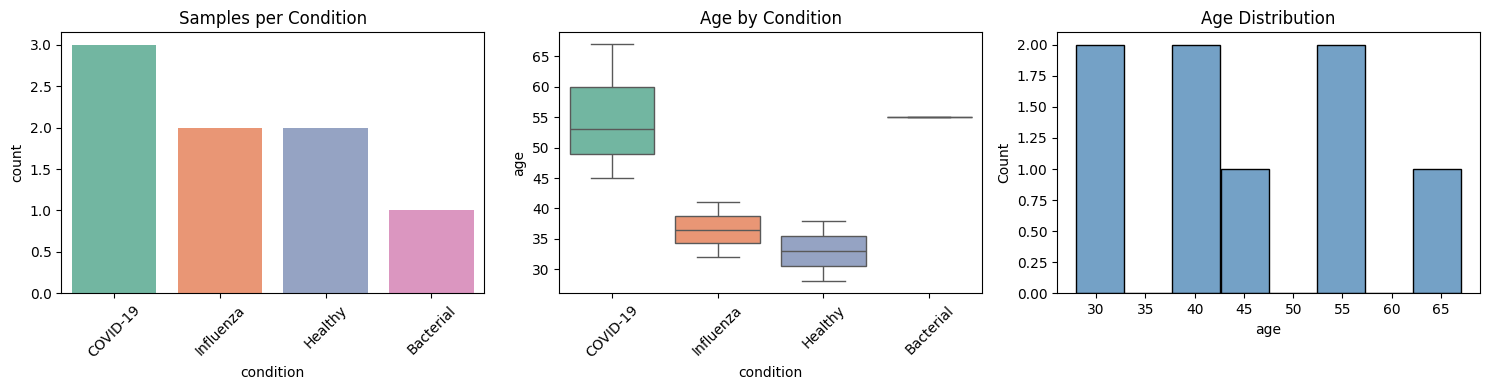

Figure saved to figures/01_cohort_overview.png


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Plot 1: Count per condition
sns.countplot(data=df, x="condition", ax=axes[0], palette="Set2")
axes[0].set_title("Samples per Condition")
axes[0].tick_params(axis='x', rotation=45)

# Plot 2: Age distribution by condition
sns.boxplot(data=df, x="condition", y="age", ax=axes[1], palette="Set2")
axes[1].set_title("Age by Condition")
axes[1].tick_params(axis='x', rotation=45)

# Plot 3: Age distribution overall
sns.histplot(data=df, x="age", bins=8, ax=axes[2], color="steelblue")
axes[2].set_title("Age Distribution")

plt.tight_layout()
plt.savefig("figures/01_cohort_overview.png", dpi=300)
plt.show()

print("Figure saved to figures/01_cohort_overview.png")

In [29]:
# Set random seed for reproducibility
np.random.seed(42)

# Real interferon-stimulated and immune genes
genes = ["IFITM3", "ISG15", "MX1", "OAS1", "IFIT1", "RSAD2", "IFI44L", 
         "SIGLEC1", "IFI27", "CXCL10", "IL6", "TNF", "IFNG", "IL1B", 
         "CCL2", "CD4", "CD8A", "FOXP3", "GZMB", "PRF1", "IL10", 
         "TGFB1", "HLA-DRA", "CD14", "FCGR3A"]

# Simulate counts for our 8 patients
# Infected patients have higher interferon-stimulated gene expression
expression_data = {}
for gene in genes:
    counts = []
    for _, row in df.iterrows():
        if row["condition"] == "Healthy":
            base = np.random.negative_binomial(5, 0.01)  # low expression
        elif gene in ["IFITM3", "ISG15", "MX1", "OAS1", "IFIT1", "RSAD2", 
                       "IFI44L", "IFI27", "CXCL10", "SIGLEC1"]:
            base = np.random.negative_binomial(20, 0.01)  # high ISG expression in infected
        else:
            base = np.random.negative_binomial(10, 0.01)  # moderate
        counts.append(base)
    expression_data[gene] = counts

# Create expression DataFrame
expr_df = pd.DataFrame(expression_data, index=df["sample_id"])
print(expr_df.shape)
print(expr_df.head())

(8, 25)
           IFITM3  ISG15   MX1  OAS1  IFIT1  RSAD2  IFI44L  SIGLEC1  IFI27  \
sample_id                                                                    
S001         2186   1694  1615  2328   1897   1377    1828     2005   1936   
S002         1899   2839  1791  2140   1447   2008    1672     1471   1425   
S003          349    541   656   324    834    604     421      621   1072   
S004         2186   1151  2646  1797   1374   2029    3427     2225   2231   
S005         1520   1867  1922  1778   1953   2027    1929     2373   2127   

           CXCL10  ...   CD4  CD8A  FOXP3  GZMB  PRF1  IL10  TGFB1  HLA-DRA  \
sample_id          ...                                                        
S001         2488  ...  1374  1060    580  1242   546  1028    844     1046   
S002         1702  ...   938   709   1467  1641   936   850    740     1206   
S003          289  ...   592   327   1477   374   313   701    753      947   
S004         1908  ...  1427   708   1319   708   

In [30]:
# This is what you do when you first get a count matrix
print("Dimensions:", expr_df.shape)
print("\nTotal counts per sample (library size):")
print(expr_df.sum(axis=1))

print("\nMean expression per gene (across all samples):")
print(expr_df.mean(axis=0).sort_values(ascending=False).head(10))

print("\nGenes with zero counts in any sample:")
print((expr_df == 0).any(axis=0).sum(), "genes have at least one zero")

Dimensions: (8, 25)

Total counts per sample (library size):
sample_id
S001    34663
S002    33054
S003    15234
S004    36349
S005    35199
S006    12789
S007    32225
S008    33802
dtype: int64

Mean expression per gene (across all samples):
IFI44L     1751.875
SIGLEC1    1719.375
MX1        1682.875
IFI27      1663.375
CXCL10     1549.000
ISG15      1542.125
IFITM3     1536.625
RSAD2      1536.500
OAS1       1487.000
IFIT1      1426.000
dtype: float64

Genes with zero counts in any sample:
0 genes have at least one zero


In [31]:
!pip install scipy

In [32]:
# Remove bacterial samples from both dataframes
df = df[df["condition"] != "Bacterial"].reset_index(drop=True)
expr_df = expr_df[expr_df.index != "S005"]
log_expr = np.log2(expr_df + 1)

print(df["condition"].value_counts())
print(f"\nExpression matrix: {expr_df.shape}")

condition
COVID-19     3
Influenza    2
Healthy      2
Name: count, dtype: int64

Expression matrix: (7, 25)


<Figure size 1200x800 with 0 Axes>

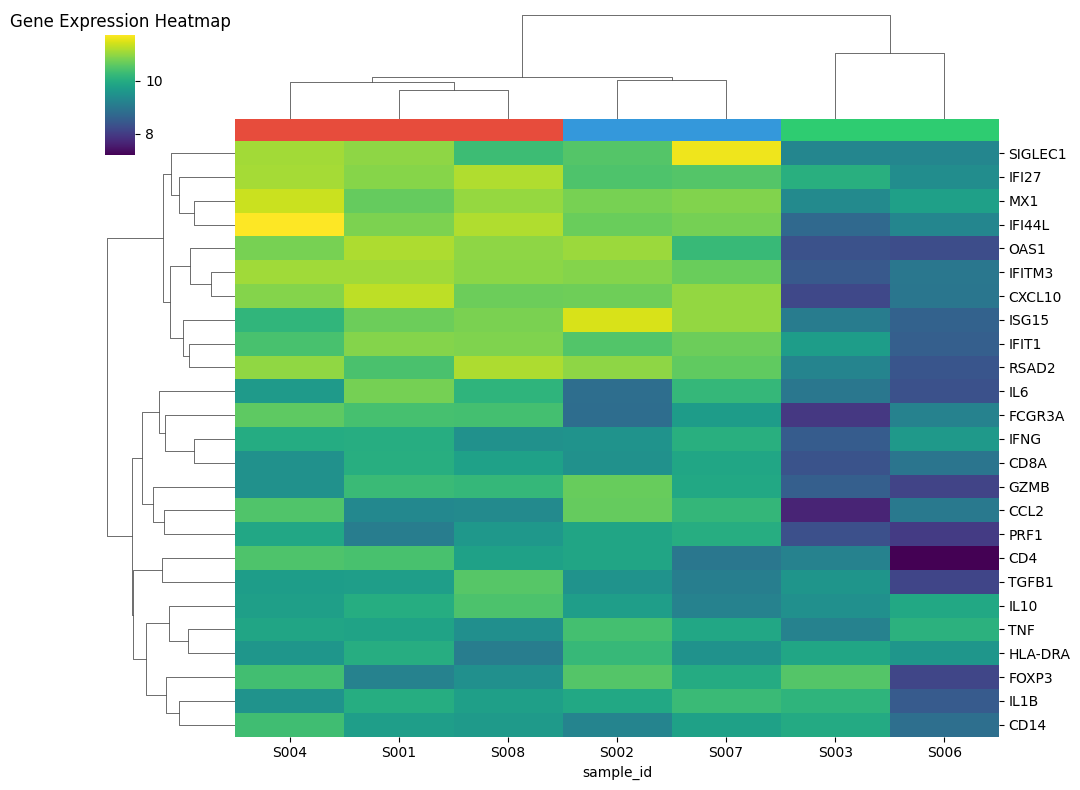

In [33]:
# Log-transform for visualization (add 1 to avoid log(0))
log_expr = np.log2(expr_df + 1)

# Merge with metadata for annotation
sample_info = df.set_index("sample_id")[["condition", "severity"]]

# Create heatmap
plt.figure(figsize=(12, 8))
sns.clustermap(log_expr.T, 
               cmap="viridis",
               col_colors=df["condition"].map({
                   "COVID-19": "#e74c3c",
                   "Influenza": "#3498db", 
                   "Bacterial": "#e67e22",
                   "Healthy": "#2ecc71"
               }).values,
               figsize=(10, 8),
               dendrogram_ratio=0.15,
               cbar_pos=(0.02, 0.8, 0.03, 0.15))
plt.title("Gene Expression Heatmap")
plt.savefig("figures/02_expression_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

/var/folders/2r/ttm59w257gd1xc0cmvkl7kj40000gn/T/ipykernel_13390/1776004050.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="condition", y="ISG_score", palette="Set2", ax=axes[0])


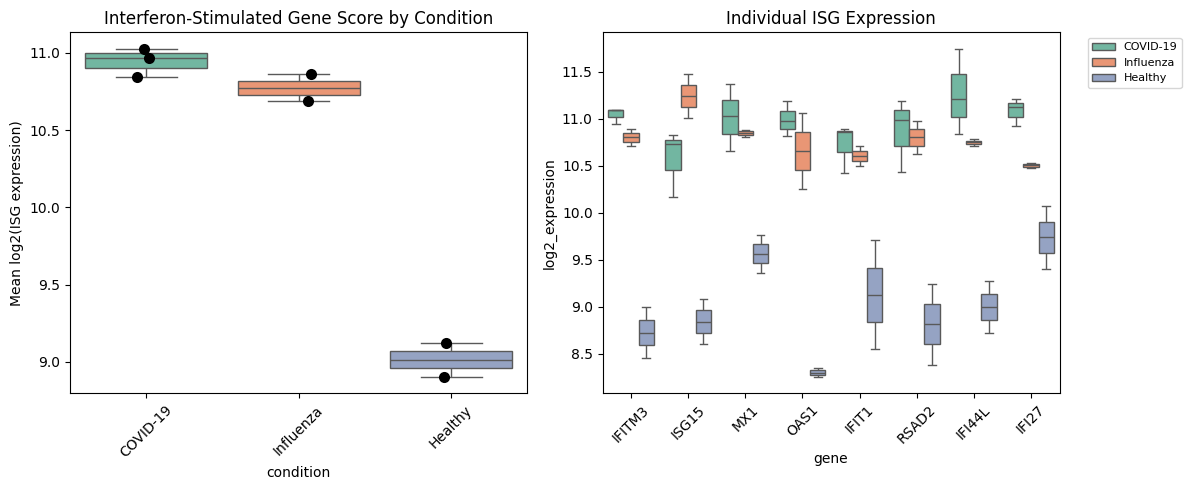

Figure saved!


In [34]:
# Define interferon-stimulated genes
isgs = ["IFITM3", "ISG15", "MX1", "OAS1", "IFIT1", "RSAD2", "IFI44L", "IFI27"]

# Calculate mean ISG score per sample
isg_score = log_expr[isgs].mean(axis=1)

# Add back to metadata
plot_df = df.copy()
plot_df["ISG_score"] = isg_score.values

# Plot ISG score by condition
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=plot_df, x="condition", y="ISG_score", palette="Set2", ax=axes[0])
sns.stripplot(data=plot_df, x="condition", y="ISG_score", color="black", size=8, ax=axes[0])
axes[0].set_title("Interferon-Stimulated Gene Score by Condition")
axes[0].set_ylabel("Mean log2(ISG expression)")
axes[0].tick_params(axis='x', rotation=45)

# Individual ISG expression across conditions
isg_melt = log_expr[isgs].copy()
isg_melt["condition"] = df["condition"].values
isg_melt = isg_melt.melt(id_vars="condition", var_name="gene", value_name="log2_expression")

sns.boxplot(data=isg_melt, x="gene", y="log2_expression", hue="condition", palette="Set2", ax=axes[1])
axes[1].set_title("Individual ISG Expression")
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)

plt.tight_layout()
plt.savefig("figures/03_isg_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved!")

In [35]:
# Save the cleaned dataframes for later use
df.to_csv("results/sample_metadata.csv", index=False)
expr_df.to_csv("results/expression_matrix.csv")

print("Data saved!")
print(f"Samples: {df.shape[0]}")
print(f"Conditions: {df['condition'].unique()}")
print(f"Genes: {expr_df.shape[1]}")

Data saved!
Samples: 7
Conditions: <StringArray>
['COVID-19', 'Influenza', 'Healthy']
Length: 3, dtype: str
Genes: 25
